# Toy learning phase diagrams — panels (a–d)

Reproduce the experiments behind `Figure5.ipynb` and `Figure5d_permutation.ipynb`
in one notebook. These correspond to **Figure 6 in the supplied screenshot / published paper**.

**Start here:** run all cells with `MODE = "saved"` for an immediate preview from the
repository's existing measurements. For new experiments, set `MODE = "retrain"` and
run all cells again. `MODE = "smoke"` runs a tiny pipeline check, not a scientific reproduction.
The training and plotting code is included below; no original notebook needs to be run first.

| Panel | Task | Horizontal sweep | Vertical sweep | Fixed embedding LR |
|---|---|---|---|---|
| (a) | Non-modular addition, regression | Decoder LR: $10^{-5}$–$10^{-2}$ | Embedding LR: $10^{-5}$–$10^{-2}$ | Swept |
| (b) | Non-modular addition, regression | Same | Decoder weight decay: 0–10 | $10^{-3}$ |
| (c) | Non-modular addition, classification | Same | Decoder weight decay: 0–20 | $10^{-3}$ |
| (d) | $S_3$ permutation composition, regression | Same | Decoder weight decay: 0–200 | $10^{-3}$ |

Source: [Liu et al., NeurIPS 2022, §4.1 and Figure 6](https://papers.nips.cc/paper_files/paper/2022/file/dfc310e81992d2e4cedc09ac47eff13e-Paper-Conference.pdf).
Implementation settings and seeds are taken from this repository's `train_add.py`,
`produce_figure_data.py`, and `Figure5d_permutation.ipynb`.

### What can be reproduced immediately?

The bundled text files contain threshold times from **10,000-step** experiments;
they are not fresh runs. The original `Figure5.ipynb` says the paper used **100,000 steps**.
Its bundled panel (c) data only cover weight decay **0–10**, whereas the screenshot extends
to **20**. This notebook leaves the unmeasured part gray. It never stretches 0–10 data to 0–20.
Use fresh training to measure the full grid. Exact phase boundaries may differ with the
training horizon, seed, PyTorch version, and phase-delay cutoff.


In [1]:
from pathlib import Path
from itertools import permutations
import hashlib
import json
import math
import platform
import time

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.ndimage import distance_transform_edt, label, uniform_filter
from IPython.display import display

# Works with the kernel started in toy/, the repository root, or a child directory.
TOY_DIR = next((candidate for parent in [Path.cwd(), *Path.cwd().parents]
                for candidate in (parent, parent / "toy")
                if (candidate / "train_add.py").is_file()), None)
if TOY_DIR is None:
    raise FileNotFoundError("Start the notebook in this repository or its toy directory.")

plt.rcParams.update({"font.family": "serif", "font.size": 12,
                     "axes.titlesize": 15, "figure.dpi": 110})
print("Toy directory:", TOY_DIR)
print("Python", platform.python_version(), "| PyTorch", torch.__version__)


Toy directory: C:\Users\caspe\OneDrive - University of Copenhagen\ATDL\grokking-squared-main\grokking-squared-main\toy
Python 3.14.3 | PyTorch 2.10.0+cpu


## Configuration

`retrain` uses 10 decoder learning rates and 11 vertical settings for (b–d),
plus a 10×10 grid for (a): **430 models**, each with at most `STEPS` updates.
The 0, 2, …, 20 grid for (c) is an explicit choice to match the screenshot's range
with the same 11-row resolution; the old generator instead uses 0, 1, …, 10.
Set `PANELS = ("d",)` to train only permutation regression.

The original notebooks use a delay cutoff of 2,000 steps for (a) and 1,000 for (b–d).
Those conventions are retained and exposed below; they are not inferred from the image
or automatically scaled with the training budget. These cutoffs and `STEPS` affect the result.

The CPU is the reproducibility default. One PyTorch thread is usually faster for these
tiny networks. The sweep runs sequentially, including on Windows, without notebook
multiprocessing issues. Completed runs are cached separately from the original results.


In [2]:
MODE = "saved"                 # "saved", "smoke", or "retrain"
PANELS = ("a", "b", "c", "d")
STEPS = 100_000                 # fresh runs; bundled results always use 10_000
DEVICE = "cpu"                 # optionally "cuda" if available
TORCH_THREADS = 1
ACCURACY_THRESHOLD = 0.90
DELAY_CUTOFF = {"a": 2000, "b": 1000, "c": 1000, "d": 1000}
SEEDS = {"a": 58, "b": 58, "c": 1, "d": 0}
SMOOTH = True                  # display only; raw grid is plotted too
UPSAMPLE = 50
CODE_VERSION = "toy-phase-v1" # bump when modifying training code to invalidate caches

assert MODE in {"saved", "smoke", "retrain"}
assert PANELS and len(set(PANELS)) == len(PANELS) and set(PANELS) <= set("abcd")
assert STEPS > 0 and 0 < ACCURACY_THRESHOLD <= 1
torch.set_num_threads(TORCH_THREADS)

RESULT_DIR = TOY_DIR / "results" / "phase_diagrams_reproduction"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

def panel_specs(mode):
    lrs = np.logspace(-5, -2, 10)
    ys = {"a": lrs.copy(), "b": np.arange(11, dtype=float),
          "c": np.arange(0, 21, 2, dtype=float),
          "d": np.array([0, 1, 2, 3, 5, 10, 20, 30, 50, 100, 200.])}
    if mode == "saved":
        # Preserve all available c measurements and show the missing 11..20 rows.
        ys["c"] = np.arange(21, dtype=float)
    if mode == "smoke":
        lrs = np.array([1e-4, 1e-3])
        ys = {"a": lrs.copy(), "b": np.array([0., 10.]),
              "c": np.array([0., 20.]), "d": np.array([0., 200.])}
    names = {"a": "Addition, regression", "b": "Addition, regression",
             "c": "Addition, classification", "d": "Permutation, regression"}
    return {p: {"x": lrs.copy(), "y": ys[p], "title": names[p],
                "task": "permutation" if p == "d" else "addition",
                "loss": "CE" if p == "c" else "MSE"} for p in PANELS}

SPECS = panel_specs(MODE)
RUN_STEPS = 200 if MODE == "smoke" else STEPS
jobs = sum(len(s["x"]) * len(s["y"]) for s in SPECS.values())
print(f"Mode: {MODE}; grid points: {jobs}")
if MODE != "saved":
    print(f"At most {jobs * RUN_STEPS:,} optimizer updates; completed runs will be reused.")


Mode: saved; grid points: 530


## Four phases from first-passage times

Let $t_{\rm train}$ and $t_{\rm test}$ be the first update at which accuracy reaches
90%. An unreached threshold is $\infty$. For the panel's cutoff $\Delta$:

| Phase | Rule | Color |
|---|---|---|
| Comprehension | Both reached, $t_{\rm test}-t_{\rm train}\leq\Delta$ | Green |
| Grokking | Both reached, $t_{\rm test}-t_{\rm train}>\Delta$ | Yellow |
| Memorization | Training reached, test not reached | Purple |
| Confusion | Training not reached | Near-black |

**Gray means missing measurements**, not confusion. If test reaches the threshold but training
does not, we classify by the failure to learn the training set (confusion).
These are first-passage labels within a finite budget, not guarantees about eventual convergence
or sustained accuracy. Fresh times count completed optimizer updates starting at 1.

Legacy files use zero-based steps and encode "not reached" as 9,999. We convert finite
times to update counts and that sentinel to infinity. The original format cannot distinguish
a true crossing on the last step from a failure. Fresh JSON records avoid that ambiguity.


In [3]:
PHASE_NAMES = ["comprehension", "grokking", "memorization", "confusion"]
PALETTE = np.array([[160, 218, 57], [253, 231, 37],
                    [70, 50, 126], [30, 30, 30]], dtype=np.uint8)
MISSING_COLOR = np.array([222, 224, 227], dtype=np.uint8)

def classify_phases(train_times, test_times, cutoff):
    train_times, test_times = np.broadcast_arrays(
        np.asarray(train_times, float), np.asarray(test_times, float))
    phase = np.full(train_times.shape, -1, dtype=int)
    observed = ~np.isnan(train_times) & ~np.isnan(test_times)
    learned_train = np.isfinite(train_times)
    learned_test = np.isfinite(test_times)
    phase[observed & ~learned_train] = 3
    phase[observed & learned_train & ~learned_test] = 2
    both = observed & learned_train & learned_test
    phase[both] = np.where(test_times[both] - train_times[both] > cutoff, 1, 0)
    return phase

def load_saved_panel(panel, spec):
    shape = (len(spec["y"]), len(spec["x"]))  # rows=y; columns=decoder LR
    train, test = np.full(shape, np.nan), np.full(shape, np.nan)
    directory = TOY_DIR / "results" / f"fig5{panel}"
    for row, y in enumerate(spec["y"]):
        for col, lr in enumerate(spec["x"]):
            if panel == "a":
                names = [f"{kind}step_eta1_{y:.5f}_eta2_{lr:.5f}.txt"
                         for kind in ("train", "test")]
            elif panel == "d":
                names = [f"{kind}_eta2_{lr:.5f}_wd_{y:.1f}.txt"
                         for kind in ("train", "test")]
            else:
                names = [f"{kind}step_eta_{lr:.5f}_wd_{y:.5f}.txt"
                         for kind in ("train", "test")]
            paths = [directory / name for name in names]
            if not all(path.exists() for path in paths):
                continue
            for matrix, path in zip((train, test), paths):
                value = float(np.loadtxt(path))
                if not np.isfinite(value) or not 0 <= value <= 9999 or value != int(value):
                    raise ValueError(f"Invalid legacy crossing time in {path}: {value}")
                matrix[row, col] = np.inf if value == 9999 else value + 1
    return {"train": train, "test": test,
            "phase": classify_phases(train, test, DELAY_CUTOFF[panel]),
            "steps": 10_000, "source": "bundled measurements"}


## Fresh training: the same toy tasks

The decoder is a two-hidden-layer tanh MLP of width 200. Addition uses 10 learned scalar
embeddings, their sum, and 45 training / 10 held-out unordered input pairs.
Regression uses 30-dimensional fixed random output templates; classification uses 19 logits.
Regression accuracy is measured by the nearest output template, not by a threshold on MSE.

Permutation regression enumerates the six elements of $S_3$ and all 36 **ordered** pairs,
using 24 training / 12 test examples. Labels follow the original convention `p2[p1]`.
Each symbol has a learned 3×3 matrix; its ordered matrix product is flattened and decoded.
This preserves the noncommutative operation. Initialization scale is 0.1 and the embedding
L1 penalty is $10^{-3}\operatorname{mean}(|E|)$, as in `Figure5d_permutation.ipynb`.

Both optimizers are AdamW; embedding weight decay is zero (equivalent to Adam here).
Fresh runs evaluate both accuracies **after the same update**; the old addition trainer
evaluates test predictions one update behind training predictions. Unused geometry/RQI
diagnostics are omitted, since phase labels depend only on threshold times.
The permutation notebook initializes an unused encoder before the decoder. We consume
the same initialization draws to preserve its seeded decoder and embedding initialization.


In [4]:
class Decoder(nn.Module):
    def __init__(self, input_dim, output_dim, width=200):
        super().__init__()
        self.l1 = nn.Linear(input_dim, width)
        self.l2 = nn.Linear(width, width)
        self.l3 = nn.Linear(width, output_dim)

    def forward(self, x):
        return self.l3(torch.tanh(self.l2(torch.tanh(self.l1(x)))))

def make_problem(task, loss_type, seed, device="cpu"):
    rng = np.random.RandomState(seed)
    torch.manual_seed(seed)
    if task == "addition":
        pairs = np.array([(a, b) for a in range(10) for b in range(a, 10)])
        classes = pairs.sum(axis=1)
        n_symbols, input_dim, n_classes, train_num = 10, 1, 19, 45
    elif task == "permutation" and loss_type == "MSE":
        perms = list(permutations(range(3)))
        lookup = {p: i for i, p in enumerate(perms)}
        pairs = np.array([(a, b) for a in range(6) for b in range(6)])
        classes = np.array([lookup[tuple(perms[b][k] for k in perms[a])]
                            for a, b in pairs])
        n_symbols, input_dim, n_classes, train_num = 6, 9, 6, 24
    else:
        raise ValueError((task, loss_type))
    output_dim = n_classes if loss_type == "CE" else 30
    # CE also draws unused templates, matching train_add's NumPy random sequence.
    templates = torch.tensor(rng.normal(size=(n_classes, output_dim)),
                             dtype=torch.float32, device=device)
    train_ids = rng.choice(len(pairs), train_num, replace=False)
    test_ids = np.setdiff1d(np.arange(len(pairs)), train_ids)
    if task == "addition":
        embeddings = nn.Parameter((torch.rand(n_symbols, input_dim) - 0.5).to(device))
        decoder = Decoder(input_dim, output_dim).to(device)
    else:
        Decoder(1, input_dim)  # original unused encoder's initialization draws
        decoder = Decoder(input_dim, output_dim).to(device)
        embeddings = nn.Parameter((torch.rand(n_symbols, input_dim) - 0.5).to(device) * 0.1)
    return dict(rng=rng, pairs=torch.tensor(pairs, device=device),
                classes=torch.tensor(classes, dtype=torch.long, device=device),
                templates=templates, train_ids=torch.tensor(train_ids, device=device),
                test_ids=torch.tensor(test_ids, device=device),
                embeddings=embeddings, decoder=decoder)

def train_one(task, loss_type, seed, eta_repr, eta_dec, weight_decay_dec,
              steps, threshold=0.9, device="cpu", record_every=100):
    if steps < 1 or record_every < 1:
        raise ValueError("steps and record_every must be positive")
    data = make_problem(task, loss_type, seed, device)
    embeddings, decoder = data["embeddings"], data["decoder"]
    train_ids, test_ids = data["train_ids"], data["test_ids"]
    targets, templates = data["classes"], data["templates"]
    opt_repr = torch.optim.AdamW([embeddings], lr=eta_repr, weight_decay=0.)
    opt_dec = torch.optim.AdamW(decoder.parameters(), lr=eta_dec,
                               weight_decay=weight_decay_dec, betas=(0.9, 0.999))

    def predict(ids):
        pairs = data["pairs"][ids]
        left, right = embeddings[pairs[:, 0]], embeddings[pairs[:, 1]]
        features = (left + right if task == "addition" else
                    torch.bmm(left.reshape(-1, 3, 3), right.reshape(-1, 3, 3)).flatten(1))
        return decoder(features)

    def accuracy(outputs, ids):
        pred = (outputs.argmax(1) if loss_type == "CE" else
                ((outputs[:, None, :] - templates[None, :, :]) ** 2).sum(2).argmin(1))
        # Integer counts avoid float32 rounding at exactly 90%.
        return (pred == targets[ids]).sum().item() / len(ids)

    first_train = first_test = None
    history = []
    started = time.perf_counter()
    for update in range(1, steps + 1):
        opt_repr.zero_grad(set_to_none=True)
        opt_dec.zero_grad(set_to_none=True)
        order = data["rng"].choice(len(train_ids), len(train_ids), replace=False)
        batch = train_ids[torch.tensor(order, device=device)]
        outputs = predict(batch)
        loss = (F.cross_entropy(outputs, targets[batch]) if loss_type == "CE" else
                F.mse_loss(outputs, templates[targets[batch]]))
        if task == "permutation":
            loss = loss + 1e-3 * embeddings.abs().mean()
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite loss at update {update}")
        loss.backward()
        opt_repr.step()
        opt_dec.step()
        with torch.no_grad():
            train_acc = accuracy(predict(train_ids), train_ids)
            test_acc = accuracy(predict(test_ids), test_ids)
        if first_train is None and train_acc >= threshold:
            first_train = update
        if first_test is None and test_acc >= threshold:
            first_test = update
        both_reached = first_train is not None and first_test is not None
        if update == 1 or update % record_every == 0 or update == steps or both_reached:
            history.append([update, train_acc, test_acc, loss.item()])
        # Once both first-passage times are known, further updates cannot alter the label.
        if both_reached:
            break
    return dict(t_train=first_train, t_test=first_test, updates_run=update,
                train_acc_at_stop=train_acc, test_acc_at_stop=test_acc, history=history,
                seconds=time.perf_counter() - started,
                train_ids=train_ids.cpu().tolist(), test_ids=test_ids.cpu().tolist())


## Run or load the sweep

Each fresh run has a JSON cache key derived from its full configuration and library versions.
Changing a learning rate, seed, budget, device, or accuracy threshold produces a different key.
To resume after interruption, rerun this cell: completed models are reused; an interrupted
model restarts from its seed. Original `fig5*` files are never overwritten or mixed into fresh runs.
The first uncached run supplies a rough runtime estimate, which can over- or underestimate
the full sweep because some runs stop early after both thresholds are reached.


In [5]:
def run_configuration(panel, x, y):
    spec = SPECS[panel]
    return dict(task=spec["task"], loss_type=spec["loss"], seed=SEEDS[panel],
                eta_repr=float(y) if panel == "a" else 1e-3,
                eta_dec=float(x), weight_decay_dec=0. if panel == "a" else float(y),
                steps=RUN_STEPS, threshold=ACCURACY_THRESHOLD, device=DEVICE,
                record_every=100)

def cached_run(config):
    metadata = dict(config=config, code_version=CODE_VERSION,
                    torch_version=str(torch.__version__), numpy_version=np.__version__,
                    python_version=platform.python_version(), threads=TORCH_THREADS)
    signature = hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:24]
    folder = RESULT_DIR / "runs"
    folder.mkdir(exist_ok=True)
    path = folder / f"{signature}.json"
    if path.exists():
        record = json.loads(path.read_text(encoding="utf-8"))
        if record["metadata"] != metadata:
            raise ValueError(f"Cache configuration mismatch: {path}")
        return record["result"], True
    result = train_one(**config)
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(dict(metadata=metadata, result=result),
                                    indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)
    return result, False

def run_panel(panel, spec):
    shape = (len(spec["y"]), len(spec["x"]))
    train, test = np.full(shape, np.nan), np.full(shape, np.nan)
    records = {}
    total, done, estimated = train.size, 0, False
    for row, y in enumerate(spec["y"]):
        for col, x in enumerate(spec["x"]):
            result, reused = cached_run(run_configuration(panel, x, y))
            train[row, col] = np.inf if result["t_train"] is None else result["t_train"]
            test[row, col] = np.inf if result["t_test"] is None else result["t_test"]
            records[(row, col)] = result
            done += 1
            if not reused and not estimated:
                seconds_per_update = result["seconds"] / result["updates_run"]
                hours = seconds_per_update * RUN_STEPS * (total - done) / 3600
                print(f"  Panel {panel}: about {hours:.2f} hours remaining if all remaining models use the full budget.", flush=True)
                estimated = True
            state = "cached" if reused else f'{result["seconds"]:.1f}s'
            print(f"  {panel}: {done}/{total} | decoder LR={x:.3g}, y={y:.3g} | "
                  f'train={result["t_train"]}, test={result["t_test"]} | {state}', flush=True)
    return dict(train=train, test=test, phase=classify_phases(train, test, DELAY_CUTOFF[panel]),
                steps=RUN_STEPS, source="fresh training", records=records)

results = {}
if MODE == "saved":
    if ACCURACY_THRESHOLD != 0.9:
        raise ValueError("Bundled times use 90%; choose retrain to change the threshold.")
    for panel, spec in SPECS.items():
        results[panel] = load_saved_panel(panel, spec)
else:
    for panel, spec in SPECS.items():
        results[panel] = run_panel(panel, spec)

for panel, result in results.items():
    counts = {name: int((result["phase"] == i).sum()) for i, name in enumerate(PHASE_NAMES)}
    counts["missing"] = int((result["phase"] < 0).sum())
    print(f"({panel}) {counts}")


(a) {'comprehension': 20, 'grokking': 4, 'memorization': 64, 'confusion': 12, 'missing': 0}
(b) {'comprehension': 12, 'grokking': 18, 'memorization': 49, 'confusion': 31, 'missing': 0}
(c) {'comprehension': 19, 'grokking': 5, 'memorization': 60, 'confusion': 26, 'missing': 100}
(d) {'comprehension': 64, 'grokking': 4, 'memorization': 29, 'confusion': 13, 'missing': 0}


## Plot the four panels

Axes always use **decoder learning rate increasing left to right**. Panel (a) has
embedding learning rate increasing upward. Weight decay increases downward in (b–d).
Panel (d) uses equally spaced **sweep positions**, labeled with the actual nonuniform
values `[0, 1, 2, 3, 5, 10, 20, 30, 50, 100, 200]`, matching the original plotting convention;
it is neither a linear nor a logarithmic weight-decay axis.

The smooth view bicubically interpolates four one-hot phase channels and takes their
argmax, as in the original notebooks. It is a visualization of discrete experiments,
not an additional measurement. Panels with missing data use the unsmoothed grid to
avoid coloring unmeasured regions. A separate raw plot shows every measured grid cell.
Labels are placed inside regions actually present in the data.


Saved: C:\Users\caspe\OneDrive - University of Copenhagen\ATDL\grokking-squared-main\grokking-squared-main\toy\results\phase_diagrams_reproduction\phase_diagrams_saved.png


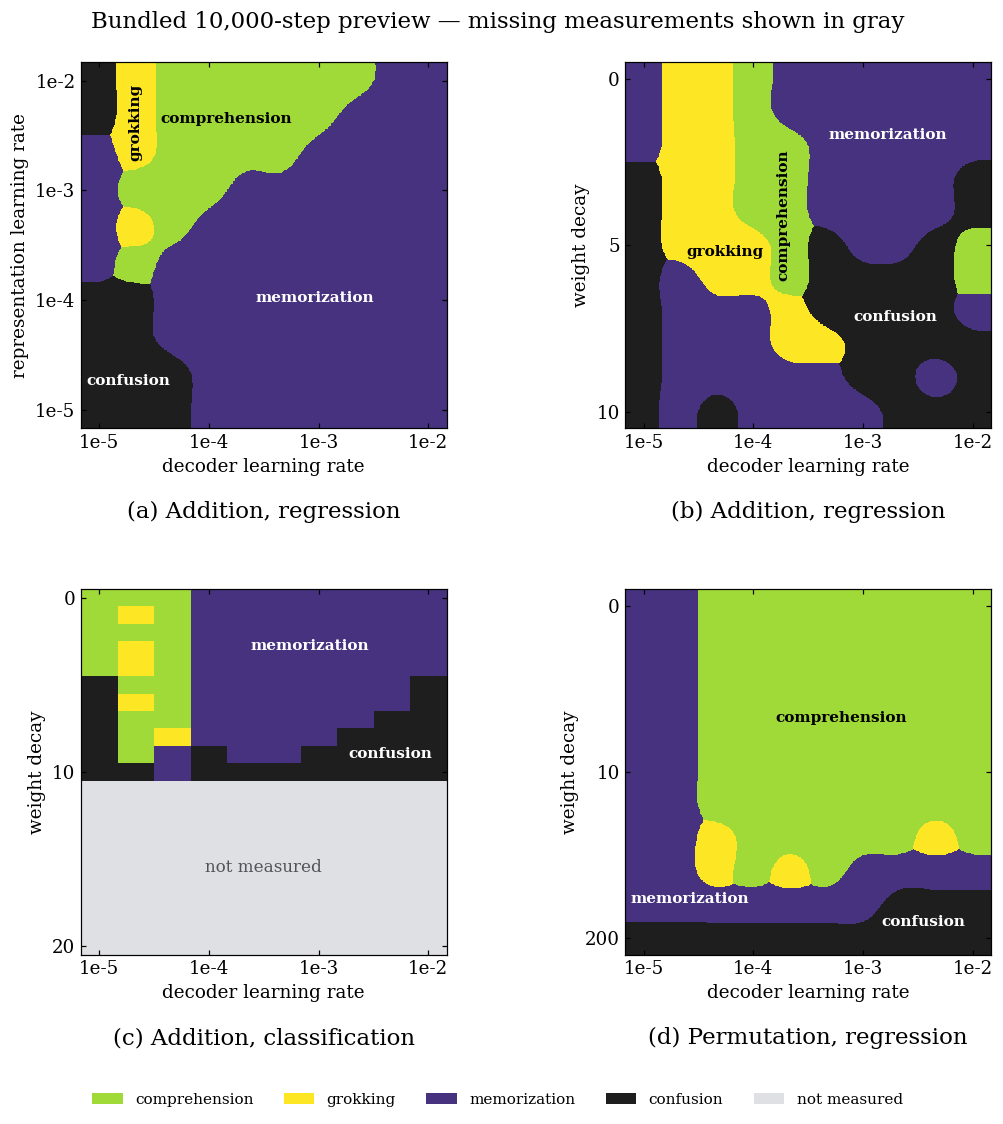

In [6]:
def phase_image(phase, smooth=True, scale=50):
    if smooth and np.all(phase >= 0):
        one_hot = torch.tensor(np.eye(4)[phase].transpose(2, 0, 1)[None], dtype=torch.float64)
        enlarged = F.interpolate(one_hot, scale_factor=scale, mode="bicubic", align_corners=False)
        classes = enlarged[0].argmax(0).numpy()
    else:
        classes = np.repeat(np.repeat(phase, scale, axis=0), scale, axis=1)
    rgb = np.empty((*classes.shape, 3), dtype=np.uint8)
    rgb[:] = MISSING_COLOR
    measured = classes >= 0
    rgb[measured] = PALETTE[classes[measured]]
    return classes, rgb

def add_region_labels(ax, classes, rows, cols):
    # Fit the entire text box inside a measured region, including at plot edges.
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    axes_box = ax.get_window_extent(renderer)
    for phase_id, name in enumerate(PHASE_NAMES):
        mask = classes == phase_id
        if not mask.any():
            continue
        components, count = label(mask)
        sizes = np.bincount(components.ravel())
        sizes[0] = 0
        region = components == sizes.argmax()
        # Padding makes even an all-one-phase image have a well-defined interior.
        distances = distance_transform_edt(np.pad(region, 1))[1:-1, 1:-1]
        text = ax.text(0, 0, name, ha="center", va="center", fontsize=10,
                       fontweight="bold", color="white" if phase_id >= 2 else "black",
                       clip_on=True)
        placed = False
        for rotation in (0, 90):
            text.set_rotation(rotation)
            box = text.get_window_extent(renderer)
            width = int(math.ceil((box.width + 8) / axes_box.width * classes.shape[1]))
            height = int(math.ceil((box.height + 8) / axes_box.height * classes.shape[0]))
            fits = uniform_filter(region.astype(float), size=(height, width),
                                  mode="constant", cval=0) > 1 - 1e-9
            if fits.any():
                row, col = np.unravel_index(np.where(fits, distances, -1).argmax(), distances.shape)
                text.set_position(((col + 0.5) / classes.shape[1] * cols - 0.5,
                                   (row + 0.5) / classes.shape[0] * rows - 0.5))
                placed = True
                break
        if not placed:
            text.remove()  # the legend still names regions too small to contain a label

def plot_phase_diagrams(results, specs, smooth=True, annotate=True):
    fig, axes = plt.subplots(2, 2, figsize=(10, 10.4))
    fig.subplots_adjust(left=0.10, right=0.97, bottom=0.16, top=0.94, hspace=0.44, wspace=0.32)
    for panel, ax in zip("abcd", axes.flat):
        if panel not in results:
            ax.set_axis_off()
            continue
        spec, result = specs[panel], results[panel]
        order = np.argsort(spec["y"])
        if panel == "a":
            order = order[::-1]
        y_values = spec["y"][order]
        phase = result["phase"][order, :]
        classes, rgb = phase_image(phase, smooth, UPSAMPLE)
        rows, cols = phase.shape
        ax.imshow(rgb, origin="upper", extent=(-0.5, cols - 0.5, rows - 0.5, -0.5),
                  interpolation="nearest", aspect="auto")
        ax.set_box_aspect(1)
        xticks = np.unique(np.linspace(0, cols - 1, min(4, cols)).round().astype(int))
        ax.set_xticks(xticks, [f"{spec['x'][i]:.0e}".replace("e-0", "e-") for i in xticks])
        yticks = np.unique(np.linspace(0, rows - 1, min(4 if panel == "a" else 3, rows)).round().astype(int))
        labels = ([f"{y_values[i]:.0e}".replace("e-0", "e-") for i in yticks]
                  if panel == "a" else [f"{y_values[i]:g}" for i in yticks])
        ax.set_yticks(yticks, labels)
        ax.set_xlabel("decoder learning rate")
        ax.set_ylabel("representation learning rate" if panel == "a" else "weight decay")
        ax.tick_params(direction="in", top=True, right=True)
        ax.set_title(f"({panel}) {spec['title']}", y=-0.27)
        if annotate:
            add_region_labels(ax, classes, rows, cols)
        if (phase < 0).any():
            missing_rows = np.flatnonzero(np.all(phase < 0, axis=1))
            if len(missing_rows):
                ax.text((cols - 1) / 2, float(np.median(missing_rows)), "not measured",
                        ha="center", va="center", color="#50545a", fontsize=11)
    incomplete = any((r["phase"] < 0).any() for r in results.values())
    source = (("Bundled 10,000-step preview" + (" — missing measurements shown in gray" if incomplete else "")) if MODE == "saved" else
              "SMOKE TEST — not a reproduction" if MODE == "smoke" else
              f"Fresh toy experiments — up to {RUN_STEPS:,} steps")
    fig.suptitle(source, fontsize=15, y=0.985)
    handles = [Patch(facecolor=PALETTE[i] / 255, label=name) for i, name in enumerate(PHASE_NAMES)]
    if any((r["phase"] < 0).any() for r in results.values()):
        handles.append(Patch(facecolor=MISSING_COLOR / 255, label="not measured"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
               fontsize=10, bbox_to_anchor=(0.5, 0.015))
    return fig

figure = plot_phase_diagrams(results, SPECS, smooth=SMOOTH)
stem = RESULT_DIR / f"phase_diagrams_{MODE}"
figure.savefig(stem.with_suffix(".png"), dpi=200, bbox_inches="tight")
figure.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
display(figure)
plt.close(figure)
print("Saved:", stem.with_suffix(".png"))


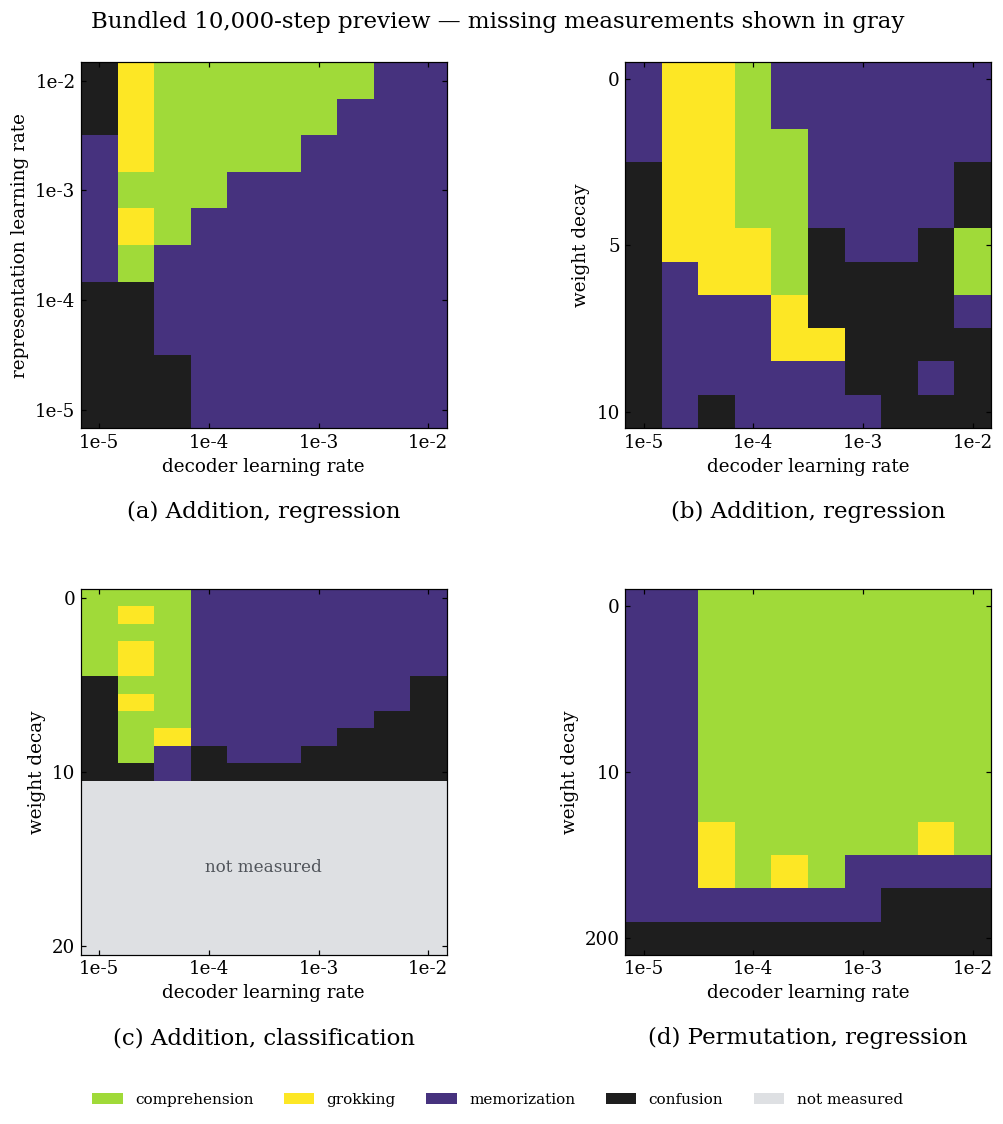

In [7]:
# Raw categorical grid: verify that smoothing has not hidden sparse measurements.
raw_figure = plot_phase_diagrams(results, SPECS, smooth=False, annotate=False)
raw_figure.savefig(RESULT_DIR / f"phase_diagrams_{MODE}_raw.png", dpi=160, bbox_inches="tight")
display(raw_figure)
plt.close(raw_figure)

# Export numeric matrices and the exact axis values for later analysis.
arrays = {}
for panel, result in results.items():
    for name in ("train", "test", "phase"):
        arrays[f"{panel}_{name}"] = result[name]
    arrays[f"{panel}_decoder_lr"] = SPECS[panel]["x"]
    arrays[f"{panel}_vertical_values"] = SPECS[panel]["y"]
    arrays[f"{panel}_steps"] = np.array(result["steps"])
    arrays[f"{panel}_delay_cutoff"] = np.array(DELAY_CUTOFF[panel])
np.savez_compressed(RESULT_DIR / f"phase_diagrams_{MODE}.npz", **arrays)


## Inspect a training trajectory (after fresh training)

The phase is determined from accuracies evaluated every update; the plotted trajectory
is stored every 100 updates plus the first and last updates. Dashed vertical lines mark
the exact first crossings. Runs stop when both crossings have been observed, so these
curves do not establish whether high accuracy is sustained afterward.


In [8]:
if MODE == "saved":
    print("Bundled files contain crossing times only. Use smoke/retrain to inspect trajectories.")
else:
    panel = "d" if "d" in results else next(iter(results))
    result = results[panel]
    candidates = np.argwhere(result["phase"] == 1)
    row, col = map(int, candidates[0]) if len(candidates) else (0, 0)
    run = result["records"][(row, col)]
    history = np.array(run["history"])
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.plot(history[:, 0], history[:, 1], label="train", color="#3264ac")
    ax.plot(history[:, 0], history[:, 2], label="test", color="#dc7a21")
    ax.axhline(ACCURACY_THRESHOLD, color="gray", ls=":", label=f"{ACCURACY_THRESHOLD:.0%} threshold")
    for key, color in (("t_train", "#3264ac"), ("t_test", "#dc7a21")):
        if run[key] is not None:
            ax.axvline(run[key], color=color, ls="--", alpha=0.7)
    ax.set(xlabel="optimizer updates", ylabel="accuracy", ylim=(-0.03, 1.05),
           title=f"Panel ({panel}), decoder LR={SPECS[panel]['x'][col]:.3g}, y={SPECS[panel]['y'][row]:g}")
    ax.legend(ncol=3, fontsize=9)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


Bundled files contain crossing times only. Use smoke/retrain to inspect trajectories.


## Interpreting a mismatch with the screenshot

1. Compare **raw grids first**. Rounded boundaries are a plotting choice, not measured precision.
2. Use `MODE = "retrain"`, `STEPS = 100_000`, and all panels for the full-range experiment.
   The saved preview is a shorter experiment and has no classification measurements above 10.
3. Check `DELAY_CUTOFF`, seeds, and the finite training horizon before interpreting a phase change.
   The repository supplies one seed per panel; this is not a seed-averaged phase diagram.
4. Inspect threshold times and sample trajectories. Missing measurements, failure to fit training
   data, and failure to generalize are different outcomes.
5. For a robustness study, repeat with other `SEEDS` and report variation. Do not tune seeds,
   flip axes, or move labels merely to make the result look like the screenshot.

Outputs are written under `toy/results/phase_diagrams_reproduction/`: PNG/PDF plots,
raw-grid PNG, numerical NPZ matrices, and (for fresh training) per-run JSON records.
Only NumPy, PyTorch, Matplotlib, SciPy and a Python Jupyter kernel are needed.
